# 02 — Return Construction

Turns prices, curves, FX and short rates into the **EUR return matrix** used by every later notebook.

1. Synthetic constant-maturity bonds from par yield curves
2. **Validation gate:** synthetic UST vs SHY / IEF / TLT — must pass before EUR and JGB synthetics are trusted
3. Synthetic EUR (AAA and all-issuer) and JGB 7–10Y bonds
4. EUR conversion: unhedged vs CIP-forward hedged
5. Final universe statistics and processed files

**Pass criteria for the gate (set before looking at results):** monthly correlation ≥ 0.97, |β − 1| ≤ 0.10, tracking error ≤ 1.5% p.a.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import data_loader as dl, returns as R, universe as U

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Synthetic constant-maturity bond

Each day the bond is a fresh par bond: on $t-1$ coupon $c=y_{t-1}$, maturity $M$. On $t$ it is repriced at the new par yield with maturity $M-\Delta t$ and the coupon accrual is added:

$$R_t = P\big(c=y_{t-1},\; y=y_t,\; T=M-\Delta t\big) - 1 + y_{t-1}\,\Delta t,\qquad
P = \frac{c}{f}\,\frac{1-(1+y/f)^{-fT}}{y/f} + (1+y/f)^{-fT}$$

The duration/convexity approximation $R_t \approx y_{t-1}\Delta t - D\,\Delta y + \tfrac12 C\,(\Delta y)^2$ is kept as a cross-check.

| Curve | Yield type | Coupon frequency $f$ |
|---|---|---|
| UST (FRED CMT) | par | 2 |
| ECB (PY) | par | 1 |
| JGB (MoF) | par | 2 |

In [2]:
d, c = R.par_bond_duration_convexity(np.array([0.01, 0.03, 0.05]), 10)
pd.DataFrame({"yield": [0.01, 0.03, 0.05], "mod. duration": d, "convexity": c})

,yield,mod. duration,convexity
0,0.0100,9.4937,97.6217
1,0.0300,8.5843,84.6227
2,0.0500,7.7946,73.6287


## 2. Validation gate: synthetic UST vs Treasury ETFs

ETF indices: SHY ≈ 1–3Y (proxy: 2Y), IEF ≈ 7–10Y (proxy: 50/50 7Y+10Y), TLT ≈ 20Y+ (proxy: 50/50 20Y+30Y). Single-maturity proxies are shown to justify the blends.

In [3]:
ust, px = dl.load_ust_curve(), dl.load_etf_prices()
single = {m: R.synthetic_bond_returns(ust[m], float(m[:-1]), 2) for m in ["2Y", "7Y", "10Y", "20Y", "30Y"]}
proxies = {
    ("SHY", "2Y"): single["2Y"],
    ("IEF", "7Y"): single["7Y"], ("IEF", "10Y"): single["10Y"],
    ("IEF", "7Y+10Y"): R.blend_returns([single["7Y"], single["10Y"]], "x"),
    ("TLT", "20Y"): single["20Y"], ("TLT", "30Y"): single["30Y"],
    ("TLT", "20Y+30Y"): R.blend_returns([single["20Y"], single["30Y"]], "x"),
}
rows = {}
for (etf, name), r in proxies.items():
    syn_idx = R.index_from_returns(r)
    for rule, ppy, label in [("ME", 12, "monthly"), ("W-WED", 52, "weekly")]:
        a = R.period_levels(syn_idx, rule).pct_change().loc["2002-09":]
        b = R.period_levels(px[etf].dropna(), rule).pct_change().loc["2002-09":]
        rows[(etf, name, label)] = R.tracking_stats(a, b, ppy)
gate = pd.DataFrame(rows).T
gate["pass"] = (gate["corr"] >= 0.97) & ((gate["beta (a on b)"] - 1).abs() <= 0.10) & (gate["TE p.a."] <= 0.015)
gate.loc[(slice(None), slice(None), "monthly"), :].round(4)

n   corr  ...  vol b p.a.   pass
SHY 2Y      monthly 290.0000 0.9854  ...      0.0149   True
IEF 7Y      monthly 290.0000 0.9839  ...      0.0664  False
    10Y     monthly 290.0000 0.9898  ...      0.0664  False
    7Y+10Y  monthly 290.0000 0.9930  ...      0.0664   True
TLT 20Y     monthly 290.0000 0.9869  ...      0.1345  False
    30Y     monthly 290.0000 0.9898  ...      0.1345  False
    20Y+30Y monthly 290.0000 0.9936  ...      0.1345  False

[7 rows x 8 columns]

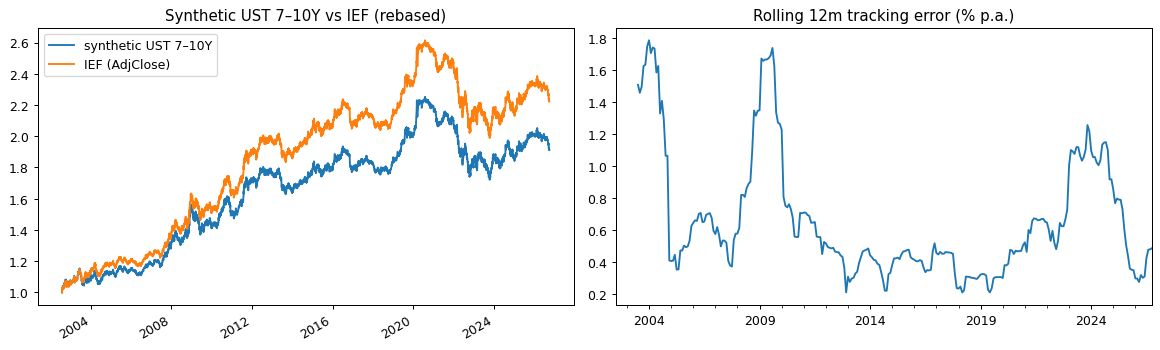

In [4]:
syn_ief = R.index_from_returns(proxies[("IEF", "7Y+10Y")]).loc["2002-07-30":]
ief = px["IEF"].dropna()
both = pd.concat([syn_ief / syn_ief.iloc[0], ief / ief.iloc[0]], axis=1, join="inner")
both.columns = ["synthetic UST 7–10Y", "IEF (AdjClose)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
both.plot(ax=ax[0], title="Synthetic UST 7–10Y vs IEF (rebased)")
m = both.resample("ME").last().pct_change()
(m.iloc[:, 0] - m.iloc[:, 1]).rolling(12).std().mul(np.sqrt(12) * 100).plot(ax=ax[1], title="Rolling 12m tracking error (% p.a.)")
plt.tight_layout(); plt.show()

In [5]:
exact = single["10Y"]
approx = R.synthetic_bond_returns(ust["10Y"], 10, 2, method="approx")
gap = (exact - approx).dropna()
print(f"Exact repricing vs duration/convexity approximation (10Y): max |daily gap| {gap.abs().max():.2e}, mean gap {gap.mean() * 252:.4%} p.a.")

Exact repricing vs duration/convexity approximation (10Y): max |daily gap| 2.80e-05, mean gap 0.0008% p.a.


**Reading the gate.** The gate is for the 7–10Y methodology (IEF) and the short end (SHY); both pass. TLT's 20Y+30Y blend misses by a hair (TE 1.52% vs 1.50%) — irrelevant for v1 because TLT enters as the ETF itself, but it shows the long end of the CMT curve is a weaker proxy. The blend is chosen over single maturities because it matches IEF's beta. A small negative mean gap is expected: a constant-maturity bond re-buys at par every day and misses the roll-down an actual 7–10Y portfolio earns on an upward-sloping curve, and on-the-run CMT yields sit slightly below off-the-run bonds held by the index.

## 3. Synthetic EUR and JGB 7–10Y bonds

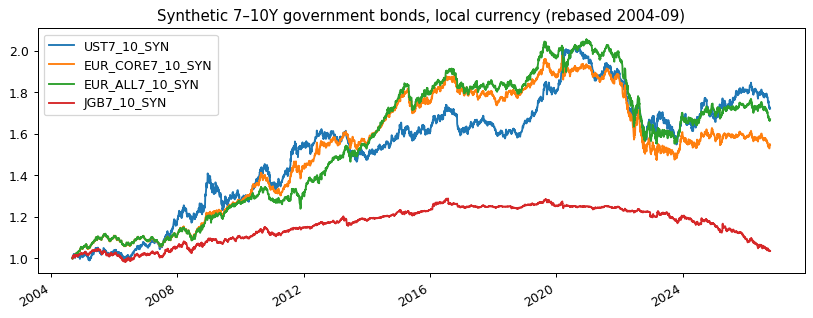

UST7_10 vs Δ UST (avg 7Y,10Y)    7.3841
EUR_CORE vs Δ AAA (avg 7Y,10Y)   7.7128
EUR_ALL vs Δ ALL (avg 7Y,10Y)    7.5208
JGB7_10 vs Δ JGB (avg 7Y,10Y)    7.9960
Name: empirical duration, dtype: float64

In [6]:
syn = U.synthetic_indices()
loc = pd.DataFrame({k: v for k, v in syn.items()}).loc["2004-09-07":].dropna()
(loc / loc.iloc[0]).plot(title="Synthetic 7–10Y government bonds, local currency (rebased 2004-09)")
plt.show()

aaa, allc = dl.load_ecb_curve("AAA"), dl.load_ecb_curve("ALL")
def emp_duration(idx, yld, start="2004-09-07"):
    """OLS slope of daily synthetic returns on daily yield changes (same window for all curves)."""
    r = idx.loc[start:].pct_change(); dy = yld.loc[start:].diff() / 100
    x = pd.concat([r, dy], axis=1, join="inner").dropna()
    return -np.polyfit(x.iloc[:, 1], x.iloc[:, 0], 1)[0]
pd.Series({
    "UST7_10 vs Δ UST (avg 7Y,10Y)": emp_duration(syn["UST7_10_SYN"], (ust["7Y"] + ust["10Y"]) / 2),
    "EUR_CORE vs Δ AAA (avg 7Y,10Y)": emp_duration(syn["EUR_CORE7_10_SYN"], (aaa["7Y"] + aaa["10Y"]) / 2),
    "EUR_ALL vs Δ ALL (avg 7Y,10Y)": emp_duration(syn["EUR_ALL7_10_SYN"], (allc["7Y"] + allc["10Y"]) / 2),
    "JGB7_10 vs Δ JGB (avg 7Y,10Y)": emp_duration(syn["JGB7_10_SYN"], (dl.load_jgb_curve()["7Y"] + dl.load_jgb_curve()["10Y"]) / 2),
}, name="empirical duration")

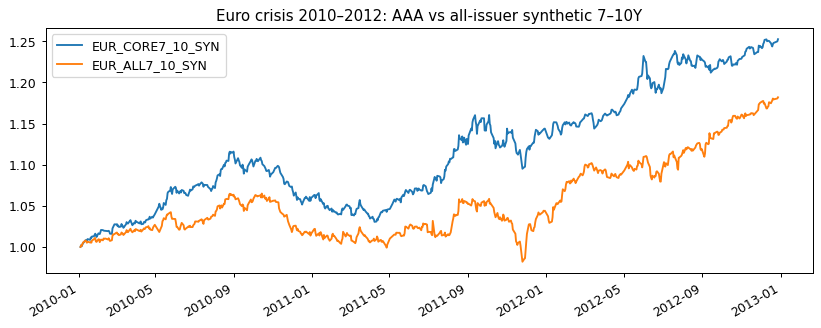

In [7]:
euro = (loc[["EUR_CORE7_10_SYN", "EUR_ALL7_10_SYN"]].loc["2010-01":"2012-12"])
(euro / euro.iloc[0]).plot(title="Euro crisis 2010–2012: AAA vs all-issuer synthetic 7–10Y")
plt.show()

## 4. EUR conversion and FX hedge

FX quotes are foreign currency per EUR ($S$). Unhedged: $1+R^{EUR} = (1+R^{fc})\,S_{t-1}/S_t$.

Hedged with a one-period CIP forward $F = S_0\,\frac{1+r_{fc}\tau_{fc}}{1+r_{EUR}\tau_{EUR}}$ (rates fixed at the period start, ACT/360 for USD and EUR, ACT/365 for JPY):

$$R^{hedged} = \frac{1+r_{EUR}\tau_{EUR}}{1+r_{fc}\tau_{fc}} - 1 + R^{fc}\,\frac{S_0}{S_1}$$

Only the gain or loss on the asset during the period remains exposed to FX.

In [8]:
h = U.eur_returns("monthly", hedge_bonds=True).loc["2007-05":]
u = U.eur_returns("monthly", hedge_bonds=False).loc["2007-05":]
bonds = ["SHY", "IEF", "TLT", "JGB7_10_SYN", "LQD", "HYG"]
ann = lambda df: (1 + df).prod() ** (12 / len(df)) - 1
pd.DataFrame({"return hedged": ann(h[bonds]), "return unhedged": ann(u[bonds]),
              "vol hedged": h[bonds].std() * np.sqrt(12), "vol unhedged": u[bonds].std() * np.sqrt(12)}).mul(100).round(2)

,return hedged,return unhedged,vol hedged,vol unhedged
SHY,1.0900,2.7700,1.5500,9.0400
IEF,2.1600,3.9300,6.8000,10.6300
TLT,1.6800,3.4500,14.3000,16.5500
JGB7_10_SYN,0.9200,-0.4300,2.4900,12.4800
LQD,2.7700,4.7300,8.2300,9.9100
HYG,3.5800,5.7100,10.1900,10.1600


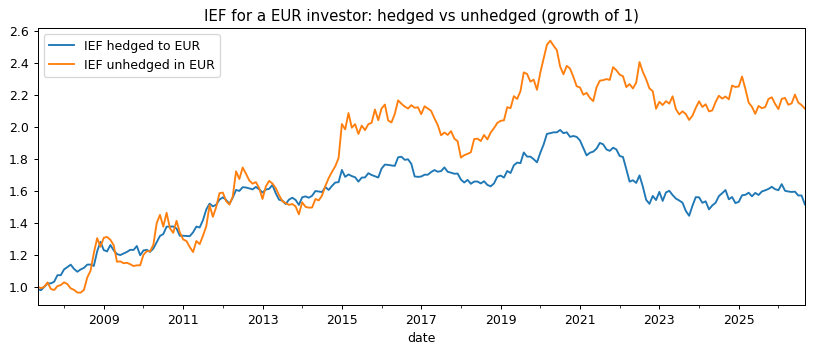

In [9]:
comp = pd.DataFrame({"IEF hedged to EUR": (1 + h["IEF"]).cumprod(), "IEF unhedged in EUR": (1 + u["IEF"]).cumprod()})
comp.plot(title="IEF for a EUR investor: hedged vs unhedged (growth of 1)"); plt.show()

## 5. Final v1 universe (EUR, policy FX treatment)

In [10]:
m = U.eur_returns("monthly").loc["2007-05":]
rf = dl.load_short_rates()["EUR"].resample("ME").mean().div(1200).reindex(m.index)
wealth = (1 + m).cumprod()
stats = pd.DataFrame({
    "sleeve": pd.Series(U.SLEEVE),
    "ann. return %": ann(m) * 100,
    "ann. vol %": m.std() * np.sqrt(12) * 100,
    "Sharpe (vs EUR O/N)": (m.sub(rf, axis=0).mean() * 12) / (m.std() * np.sqrt(12)),
    "max drawdown %": (wealth / wealth.cummax() - 1).min() * 100,
}).loc[m.columns]
print(f"{m.index[0]:%Y-%m} → {m.index[-1]:%Y-%m}, {len(m)} months")
stats.round(2)

2007-05 → 2026-09, 233 months


,sleeve,ann. return %,ann. vol %,Sharpe (vs EUR O/N),max drawdown %
SPY,equity,11.8800,14.3200,0.8000,-46.7800
VGK,equity,5.5800,14.8800,0.3800,-54.2300
EWJ,equity,5.5900,13.9000,0.4000,-45.1000
SHY,govt,1.0900,1.5500,0.1500,-7.7000
IEF,govt,2.1600,6.8000,0.2200,-27.0700
TLT,govt,1.6800,14.3000,0.1300,-51.1500
EUR_CORE7_10_SYN,govt,1.8000,5.5000,0.1900,-24.4500
JGB7_10_SYN,govt,0.9200,2.4900,0.0300,-12.6100
LQD,credit,2.7700,8.2300,0.2700,-26.0100
HYG,credit,3.5800,10.1900,0.3100,-30.3300


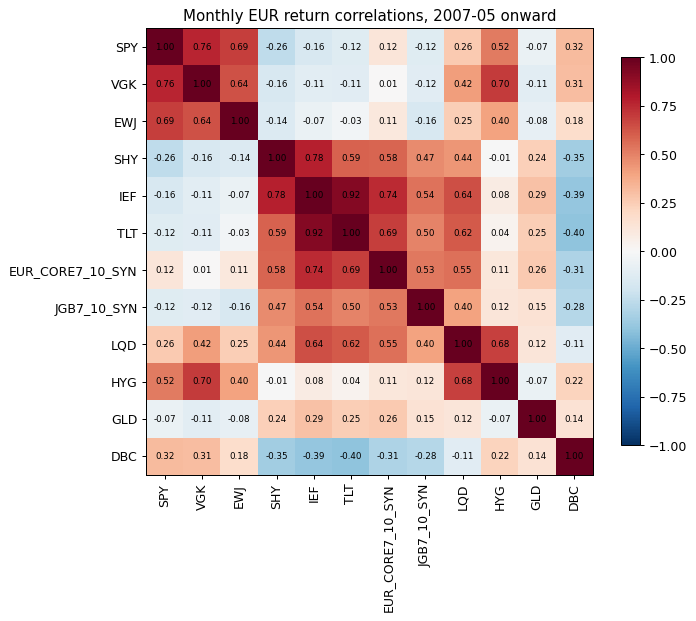

In [11]:
corr = m[U.ASSETS].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Monthly EUR return correlations, 2007-05 onward"); plt.show()

In [12]:
out = ROOT / "data" / "processed"; out.mkdir(parents=True, exist_ok=True)
for freq in ["daily", "weekly", "monthly"]:
    U.eur_returns(freq).to_csv(out / f"asset_returns_eur_{freq}.csv")
    U.eur_returns(freq, hedge_bonds=False).to_csv(out / f"asset_returns_eur_{freq}_unhedged.csv")
sorted(p.name for p in out.glob("*.csv"))

['asset_returns_eur_daily.csv', 'asset_returns_eur_daily_unhedged.csv', 'asset_returns_eur_monthly.csv', 'asset_returns_eur_monthly_unhedged.csv', 'asset_returns_eur_weekly.csv', 'asset_returns_eur_weekly_unhedged.csv', 'backtest_daily_gross.csv', 'backtest_daily_net.csv']

## Takeaways

* **Gate passed.** The synthetic UST 7–10Y (50/50 7Y+10Y) tracks IEF with monthly correlation 0.993, β 0.99 and 0.78% p.a. tracking error; SHY passes as well. The same repricing code therefore builds the EUR and JGB bonds. Exact repricing and the duration/convexity approximation differ by < 0.001% p.a.
* **Euro crisis is visible only in the all-issuer curve.** Jul–Nov 2011: AAA synthetic +4.2%, all-issuer −2.1%. Over 2010–2012 the gap is 25.3% vs 18.2%. The investable bond uses AAA (labelled *core*); stress tests rerun with the all-issuer version.
* **FX hedging dominates foreign bond risk.** For a EUR investor, unhedged IEF has 10.6% volatility vs 6.8% hedged; unhedged JGB 12.5% vs 2.5%. Unhedged returns were higher only because the USD appreciated (EURUSD ≈ 1.35 → 1.17) — a bet, not a bond premium.
* **2022 in EUR:** equities −11% to −13%, IEF −17%, TLT −33%, EUR core −19%, gold +5%, commodities +26%. The SPY–IEF monthly correlation moved from −0.36 (2007–2020) to +0.27 (2021–) — the diversification break notebook 07 quantifies.
* **Output:** `data/processed/asset_returns_eur_{daily,weekly,monthly}[_unhedged].csv`, 2007-05 → 2026-09 (233 months) for the common sample.

Next: notebook 03 — covariance estimators (Sample, Rolling, EWMA, Ledoit-Wolf, GARCH-CCC) on weekly returns.